# LPT-R Thresholding with iNat Models

The goal of this notebook is to apply LPT-R to predicted probabilities for taxa using models trained on iNat data.

This reproduces Dorm et al's LPT-R thresholding technique.

In [2]:
import os
from pathlib import Path
import sys

import h3
import h3pandas
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pydeck as pdk
from shapely.geometry import shape
from sklearn.metrics import precision_score, recall_score, f1_score
import tensorflow as tf
from tqdm.auto import tqdm

In [3]:
sys.path.append('..')

In [4]:
from lib.models.tf_gp_model import TFGeoPriorModel
from lib.models.encoders import CoordEncoder

In [64]:
GEOMODEL_PATH = "/home/alex/export_eval_models/model_exports/tf_geoprior_2_20_r6_elevation.h5"
ELEVATION_RASTER_PATH = "/home/alex/sinr/data/env/elev_scaled.npy"
INPUT_ENCODING = "sinusoidal"
TAX_2_20_FILE = "/data-ssd/alex/datasets/vision-export-20250119070012-aka-2.20/taxonomy.csv"
TAXON_RANGE_CSVS_DIR = "/data-ssd/alex/datasets/vision-export-20250216070017-aka-2.21/taxon_range_csvs/"
TARGET_TAXON_ID = 13270
SPATIAL_DATA_2_20_FILE = "/data-ssd/alex/datasets/vision-export-20250119070012-aka-2.20/spatial_data.parquet"
SPATIAL_DATA_2_20_H3_FILE = "/data-ssd/alex/datasets/vision-export-20250119070012-aka-2.20/spatial_data_h3.parquet"

In [65]:
model = TFGeoPriorModel(GEOMODEL_PATH)
raster = np.load(ELEVATION_RASTER_PATH).astype(np.float32)
encoder = CoordEncoder(INPUT_ENCODING, raster=raster)
tax_2_20 = pd.read_csv(TAX_2_20_FILE)

In [66]:
def coord_grid(grid_size):
    feats = np.zeros(
        (grid_size[0], grid_size[1], 2),
        dtype=np.float32
    )
    mg = np.meshgrid(
        np.linspace(-180, 180, feats.shape[1]),
        np.linspace(90, -90, feats.shape[0]),
    )
    feats[:, :, 0] = mg[0]
    feats[:, :, 1] = mg[1]
    
    return feats.reshape(feats.shape[0] * feats.shape[1], 2)

# ok let's load the known range

In [67]:
known_range = pd.read_csv(
    Path(TAXON_RANGE_CSVS_DIR) / f"{TARGET_TAXON_ID}.csv",
    names=["h3_04"],
)

In [68]:
layer = pdk.Layer(
    "H3HexagonLayer",
    known_range,
    pickable=True,
    stroked=True,
    filled=True,
    extruded=False,
    get_hexagon="h3_04",
    get_fill_color="[0, 255, 255]",
    get_line_color="[0, 255, 255]",
    line_width_min_pixels=2,
)
view_state = pdk.ViewState(
    latitude=37.7749295, 
    longitude=-90.4194155, 
    zoom=2, 
    bearing=0, 
    pitch=0
)
r = pdk.Deck(
    layers=[layer], 
    initial_view_state=view_state, 
    tooltip={"text": "Score: {preds}"}
)
r.show()

# ok let's load the training data

In [69]:
spatial_train = pd.read_parquet(SPATIAL_DATA_2_20_FILE)

In [70]:
spatial_train_13270 = spatial_train[(spatial_train.taxon_id==TARGET_TAXON_ID)&(spatial_train.community==1)]

In [71]:
spatial_train_13270_h3 = spatial_train_13270.h3.geo_to_h3(
    resolution=4,
    lat_col="latitude",
    lng_col="longitude"
)
spatial_train_13270_h3.reset_index(inplace=True)

In [72]:
layer = pdk.Layer(
    "H3HexagonLayer",
    spatial_train_13270_h3[["h3_04"]],
    pickable=True,
    stroked=True,
    filled=True,
    extruded=False,
    get_hexagon="h3_04",
    get_fill_color="[0, 255, 255]",
    get_line_color="[0, 255, 255]",
    line_width_min_pixels=2,
)
view_state = pdk.ViewState(
    latitude=37.7749295, 
    longitude=-90.4194155, 
    zoom=2, 
    bearing=0, 
    pitch=0
)
r = pdk.Deck(
    layers=[layer], 
    initial_view_state=view_state, 
)
r.show()

# ok let's get the model predictions for this taxon and map it with a fixed threshold of 0.001

In [135]:
res0_cells = h3.get_res0_indexes()
all_cells = set()
for res0 in tqdm(res0_cells):
    children = h3.h3_to_children(res0, 4)
    all_cells.update(children)
    
cells_df = pd.DataFrame({"h3_04": list(all_cells)})
cells_df.set_index("h3_04", inplace=True)

  0%|          | 0/122 [00:00<?, ?it/s]

In [136]:
dfh3 = cells_df.h3.h3_to_geo()
dfh3["lng"] = dfh3.geometry.x
dfh3["lat"] = dfh3.geometry.y
_ = dfh3.pop("geometry")

In [137]:
target_class_id = int(tax_2_20[tax_2_20.taxon_id==TARGET_TAXON_ID].iloc[0].leaf_class_id)

In [138]:
locs = dfh3[["lng", "lat"]].values
encoded_locs = encoder.encode(locs)
geo_model_features = model.get_loc_emb(encoded_locs)
preds = model.eval_one_class_from_feats(
    geo_model_features,
    class_of_interest=target_class_id
)
dfh3["preds"] = preds[0]
dfh3.reset_index(inplace=True)

In [139]:
layer = pdk.Layer(
    "H3HexagonLayer",
    dfh3[dfh3.preds>0.001],
    pickable=True,
    stroked=True,
    filled=True,
    extruded=False,
    get_hexagon="h3_04",
    get_fill_color="[0, 255, 255]",
    get_line_color="[0, 255, 255]",
    line_width_min_pixels=2,
)
view_state = pdk.ViewState(
    latitude=37.7749295, 
    longitude=-90.4194155, 
    zoom=2, 
    bearing=0, 
    pitch=0
)
r = pdk.Deck(
    layers=[layer], 
    initial_view_state=view_state, 
)
r.show()

# simple calculation of LPT-R threshold

In [116]:
spatial_train_13270 = spatial_train[(spatial_train.taxon_id==TARGET_TAXON_ID)]
spatial_train_13270_h3 = spatial_train_13270.h3.geo_to_h3(
    resolution=4,
    lat_col="latitude",
    lng_col="longitude"
)
spatial_train_13270_h3.reset_index(inplace=True)
presence_preds = dfh3[dfh3['h3_04'].isin(spatial_train_13270_h3['h3_04'])]
lpt_r_threshold = np.percentile(presence_preds.preds, 5)
print(f"calculated LPT-R threshold is {lpt_r_threshold}")

calculated LPT-R threshold is 0.0023489281069487334


# let's compare this with the technique from the paper

In [84]:
# this will take a minute with a large spatial train file
spatial_train_h3 = spatial_train.h3.geo_to_h3(
    resolution=4,
    lat_col="latitude",
    lng_col="longitude"
)

In [119]:
# make presence absence dataframe
all_spatial_grid_counts = spatial_train_h3.index.value_counts()
presence_absence = pd.DataFrame({
    "background": all_spatial_grid_counts,
})
presence_absence = presence_absence.fillna(0)
target_spatial_grid_counts = spatial_train_h3[spatial_train_h3.taxon_id==TARGET_TAXON_ID].index.value_counts()  
presence_absence["forground"] = target_spatial_grid_counts
presence_absence["predictions"] = dfh3.set_index("h3_04")["preds"]
presence_absence.forground = presence_absence.forground.fillna(0)
presences = presence_absence[(presence_absence["forground"]>0)]["predictions"]
lpt_r_thresh_paper_technique = np.percentile(presences, 5)

In [140]:
lpt_r_threshold == lpt_r_thresh_paper_technique

True

# now that we have the training presences, we can calculate the LPT-R threshold at 5% and then map it

In [142]:
dfh3['binary_lpt_r'] = (dfh3['preds'] >= lpt_r_threshold).astype(int)
dfh3_clipped_lpt_r_5 = dfh3[dfh3.binary_lpt_r==1]

In [145]:
layer = pdk.Layer(
    "H3HexagonLayer",
    dfh3_clipped_lpt_r_5,
    pickable=True,
    stroked=True,
    filled=True,
    extruded=False,
    get_hexagon="h3_04",
    get_fill_color="[0, 255, 255]",
    get_line_color="[0, 255, 255]",
    line_width_min_pixels=2,
)

view_state = pdk.ViewState(
    latitude=37.7749295, 
    longitude=-90.4194155, 
    zoom=2, 
    bearing=0, 
    pitch=0
)
r = pdk.Deck(
    layers=[layer], 
    initial_view_state=view_state, 
    tooltip={"text": "Score: {preds}"}
)
r.show()

# sanity check

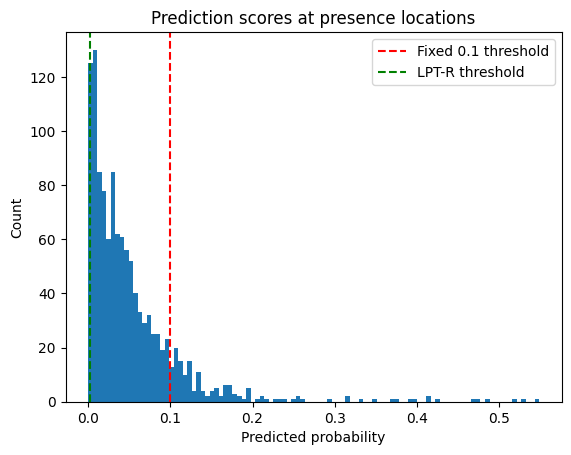

In [147]:
plt.hist(presence_preds.preds, bins=100)
plt.axvline(0.1, color='red', linestyle='--', label='Fixed 0.1 threshold')
plt.axvline(lpt_r_threshold, color='green', linestyle='--', label='LPT-R threshold')
plt.title("Prediction scores at presence locations")
plt.xlabel("Predicted probability")
plt.ylabel("Count")
plt.legend()
plt.show()

# calculate f1

In [149]:
all_cells = dfh3["h3_04"]

In [150]:
predicted_cells = set(dfh3[dfh3['binary_lpt_r'] == 1]['h3_04'])
y_pred = [1 if cell in predicted_cells else 0 for cell in all_cells]

In [152]:
true_cells = set(known_range["h3_04"])
y_true = [1 if cell in true_cells else 0 for cell in all_cells]

In [154]:
precision = precision_score(y_true, y_pred)
precision

0.7324468085106383

In [155]:
recall = recall_score(y_true, y_pred)
recall

0.8507877664504171

In [156]:
f1 = f1_score(y_true, y_pred)
f1

0.7871945119336858

# old method threshold

In [157]:
old_method_threshold = 0.0029526805

In [158]:
lpt_r_threshold, old_method_threshold

(0.0023489281069487334, 0.0029526805)

In [159]:
predicted_cells = set(dfh3[dfh3['preds'] > old_method_threshold]['h3_04'])
y_pred = [1 if cell in predicted_cells else 0 for cell in all_cells]

In [160]:
precision = precision_score(y_true, y_pred)
precision

0.8144673123486683

In [161]:
recall = recall_score(y_true, y_pred)
recall

0.8313253012048193

In [162]:
f1 = f1_score(y_true, y_pred)
f1

0.8228099678948173

# ok let's get all the cells at a resolution

In [190]:
taxon_ids = [
    13270
]
taxon_range_csvs = Path(TAXON_RANGE_CSVS_DIR)
f1s = []

In [188]:
for i in range(len(taxon_ids)):
    print("in for loop")
    taxon_id = taxon_ids[i]
    class_of_interest = int(tax_2_20[tax_2_20.taxon_id==taxon_id].iloc[0].leaf_class_id)
    print("got class of interest")
    
    preds = model.eval_one_class_from_feats(
        geo_model_features,
        class_of_interest=class_of_interest
    )
    dfh3["preds"] = preds[0]
    print("got preds")
    
    spatial_train_class = spatial_train[(spatial_train.taxon_id==taxon_id)]
    spatial_train_class_h3 = spatial_train_class.h3.geo_to_h3(
        resolution=4,
        lat_col="latitude",
        lng_col="longitude"
    )
    spatial_train_class_h3.reset_index(inplace=True)
    print("got spatial train h3 for class")

    presence_preds = dfh3[dfh3['h3_04'].isin(spatial_train_class_h3['h3_04'])]
    lpt_r_threshold = np.percentile(presence_preds.preds, 5)
    print(lpt_r_threshold)

    range_file = taxon_range_csvs / f"{taxon_id}.csv"
    if os.path.exists(range_file):
        known_range = pd.read_csv(range_file, names=["h3_04"])
        print("got known range")
        dfh3['binary_lpt_r'] = (dfh3['preds'] >= lpt_r_threshold).astype(int)
        print("got binary lpt r stuff")
        
        all_cells = dfh3["h3_04"]
        predicted_cells = set(dfh3[dfh3['binary_lpt_r'] == 1]['h3_04'])
        print("got predicted cells")
        
        y_pred = [1 if cell in predicted_cells else 0 for cell in all_cells]
        print("got y pred")
        
        true_cells = known_range.values
        y_true = [1 if cell in true_cells else 0 for cell in all_cells]

        print("got y true")
        
        precision = precision_score(y_true, y_pred)
        recall = recall_score(y_true, y_pred)
        f1 = f1_score(y_true, y_pred)
        f1s.append(f1)
    else:
        pass
        
np.array(f1s).mean()

before path
before for loop
in for loop
got class of interest
got preds
got spatial train h3 for class
0.0023489281069487334
got known range
got binary lpt r stuff
got predicted cells
got y pred
got y true


0.7871945119336858

# let's try visualizing the expert range map as a line

In [191]:
known_range = pd.read_csv(
    "/data-ssd/alex/datasets/vision-export-20250216070017-aka-2.21/taxon_range_csvs/13270.csv",
    names=["asdf"],
)

known_range_geojson_polys = h3.h3_set_to_multi_polygon(known_range.asdf.values, geo_json=True)

In [192]:
expert_range_features = []

for poly in tqdm(known_range_geojson_polys):
    outer = poly[0]
    holes = poly[1:] if len(poly) > 1 else []
    coords = [outer] + holes  # GeoJSON format
    expert_range_features.append({
        "type": "Feature",
        "geometry": {
            "type": "Polygon",
            "coordinates": coords
        },
        "properties": {"name": "Expert Range"}
    })

expert_range_features = {
    "type": "FeatureCollection",
    "features": expert_range_features
}

  0%|          | 0/5 [00:00<?, ?it/s]

In [194]:
geojson_known_range_layer = pdk.Layer(
    "GeoJsonLayer",
    data=expert_range_features,
    stroked=True,
    filled=False,
    get_line_color=[255, 255, 255],
    line_width_min_pixels=1,
    pickable=True,
)
view_state = pdk.ViewState(
    latitude=37.5,
    longitude=-122,
    zoom=2,
    bearing=0,
    pitch=0,
)
r = pdk.Deck(
    layers=[geojson_known_range_layer],
    initial_view_state=view_state,
)
r.show()

In [195]:
geojson_polys_predicted = h3.h3_set_to_multi_polygon(predicted_cells, geo_json=True)
predicted_feats = []

for poly in tqdm(geojson_polys_predicted):
    outer = poly[0]
    holes = poly[1:] if len(poly) > 1 else []
    coords = [outer] + holes  # GeoJSON format
    predicted_feats.append({
        "type": "Feature",
        "geometry": {
            "type": "Polygon",
            "coordinates": coords
        },
        "properties": {"name": "Predicted Range"}
    })

geojson_predicted = {
    "type": "FeatureCollection",
    "features": predicted_feats
}

geojson_predicted_range_layer = pdk.Layer(
    "GeoJsonLayer",
    data=geojson_predicted,
    stroked=False,
    filled=True,
    get_fill_color=[0, 200, 100, 120],  # green-ish
    get_line_color=[0, 0, 0],
    line_width_min_pixels=1,
    pickable=True,
)


  0%|          | 0/41 [00:00<?, ?it/s]

In [196]:
view_state = pdk.ViewState(
    latitude=37.5,
    longitude=-122,
    zoom=2,
    bearing=0,
    pitch=0,
)
r = pdk.Deck(
    layers=[geojson_predicted_range_layer, geojson_known_range_layer],
    initial_view_state=view_state,
)
r.show()